In [1]:
from collections import Counter
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

--- 
## 1. Pembentukan Graf Berarah (5 Vertex)
Simpul $V = \{A, B, C, D, E\}$ berjumlah $N = 5$ dan sisi berarah $E = 7$.

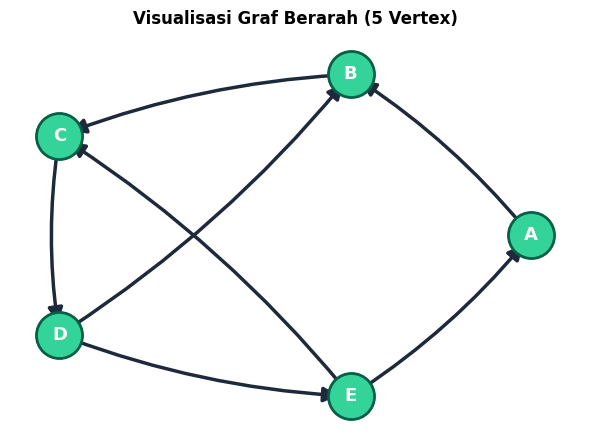

In [2]:
# Inisialisasi graf berarah
DG = nx.DiGraph()

# 5 simpul (vertex)
vertices = ['A', 'B', 'C', 'D', 'E']
DG.add_nodes_from(vertices)

# sisi berarah 
edges_directed = [
    ('A', 'B'),  # A -> B
    ('B', 'C'),  # B -> C
    ('C', 'D'),  # C -> D
    ('D', 'B'),  # D -> B 
    ('D', 'E'),  # D -> E
    ('E', 'C'),  # E -> C
    ('E', 'A')   # E -> A 
]
DG.add_edges_from(edges_directed)

# Visualisasi Graf Berarah
plt.figure(figsize=(6, 4.5))
pos = nx.circular_layout(DG)
nx.draw_networkx_nodes(DG, pos, node_size=1100, node_color='#34d399', edgecolors='#065f46', linewidths=2)
nx.draw_networkx_edges(
    DG, pos,
    width=2.5,
    edge_color='#1e293b',
    arrows=True,
    arrowsize=22,
    arrowstyle='-|>',
    connectionstyle='arc3,rad=0.08'
)
nx.draw_networkx_labels(DG, pos, font_size=13, font_weight='bold', font_color='#ffffff')
plt.title("Visualisasi Graf Berarah (5 Vertex)", fontsize=12, fontweight='bold', pad=12)
plt.axis('off')
plt.tight_layout()
plt.show()

--- 
## 2. Perhitungan 8 Karakteristik Graf Berarah

In [4]:
N = DG.number_of_nodes()  # 5 vertex
E = DG.number_of_edges()  # 7 edge

# 1. DEGREE (IN-DEGREE, OUT-DEGREE, & TOTAL DEGREE)
in_degrees = dict(DG.in_degree())
out_degrees = dict(DG.out_degree())
tot_degrees = {node: in_degrees[node] + out_degrees[node] for node in vertices}

df_degree = pd.DataFrame({
    'In-Degree (k_in)': in_degrees,
    'Out-Degree (k_out)': out_degrees,
    'Total Degree (k_tot)': tot_degrees
})
print("1. DEGREE (DERAJAT SIMPUL BERARAH):")
display(df_degree)
print(f"   Total In-Degree  = {sum(in_degrees.values())}  [Sama dengan E = {E}]")
print(f"   Total Out-Degree = {sum(out_degrees.values())}  [Sama dengan E = {E}]")
print(f"   Total Degree     = {sum(tot_degrees.values())}  [Sama dengan 2 * E = {2*E}]")

# 2. DISTRIBUSI DERAJAT: P(k) = N_k / N
in_counts = Counter(in_degrees.values())
out_counts = Counter(out_degrees.values())

print("\n2. DISTRIBUSI DERAJAT P(k):")
print("   a. Distribusi In-Degree (P_in(k)):")
for k, count in sorted(in_counts.items()):
    prob = count / N
    print(f"      P_in(k = {k}) = {count}/{N} = {prob:.2f} ({prob * 100:.1f}%)")

print("   b. Distribusi Out-Degree (P_out(k)):")
for k, count in sorted(out_counts.items()):
    prob = count / N
    print(f"      P_out(k = {k}) = {count}/{N} = {prob:.2f} ({prob * 100:.1f}%)")

# 3. AVERAGE DEGREE
avg_in = sum(in_degrees.values()) / N
avg_out = sum(out_degrees.values()) / N
avg_tot = sum(tot_degrees.values()) / N

print("\n3. AVERAGE DEGREE:")
print(f"   Average In-Degree  <k_in>  = E / N = {E}/{N} = {avg_in:.2f}")
print(f"   Average Out-Degree <k_out> = E / N = {E}/{N} = {avg_out:.2f}")
print(f"   Average Total Degree <k>   = 2E / N = {2*E}/{N} = {avg_tot:.2f}")

# 4. DENSITY (KEPADATAN GRAF BERARAH): E / [N(N-1)]
density_manual = E / (N * (N - 1))
density_nx = nx.density(DG)
print("\n4. DENSITY (KEPADATAN GRAF BERARAH):")
print(f"   Rumus: E / [N * (N - 1)] = {E} / ({N} * {N-1}) = {E}/{N*(N-1)} = {density_manual:.4f}")
print(f"   Hasil nx.density(DG) = {density_nx:.4f} ({density_nx * 100:.1f}%)")

# 5. KOEFISIEN KLASTERISASI (CLUSTERING COEFFICIENT)
clustering_local_dir = nx.clustering(DG)
avg_clustering_dir = nx.average_clustering(DG)
print("\n5. KOEFISIEN KLASTERISASI (CLUSTERING COEFFICIENT):")
print("   Koefisien Klasterisasi tiap simpul (C_i):")
for node, c in clustering_local_dir.items():
    print(f"      Simpul {node} : C_{node} = {c:.4f}")
print(f"   Rata-rata Koefisien Klasterisasi <C> = {avg_clustering_dir:.4f}")

# 6. JALUR TERPENDEK (SHORTEST PATH BERARAH)
all_paths_dir = dict(nx.all_pairs_shortest_path(DG))
all_lengths_dir = dict(nx.all_pairs_shortest_path_length(DG))

print("\n6. JALUR TERPENDEK (SHORTEST PATH DARI SOURCE KE TARGET):")
for u in vertices:
    for v in vertices:
        if u != v:
            if v in all_paths_dir[u]:
                path = all_paths_dir[u][v]
                dist = all_lengths_dir[u][v]
                print(f"   Jalur {u} -> {v} : {' -> '.join(path)} (Jarak = {dist})")
            else:
                print(f"   Jalur {u} -> {v} : Tidak ada jalur terhubung")

# Matriks Jarak Jalur Terpendek Berarah
df_dist_matrix_dir = pd.DataFrame(all_lengths_dir).T[vertices].reindex(vertices)

# 7. DIAMETER JARINGAN & JARAK RATA-RATA
if nx.is_strongly_connected(DG):
    diameter_dir = nx.diameter(DG)
    avg_distance_dir = nx.average_shortest_path_length(DG)
    print("\n7. DIAMETER JARINGAN & JARAK RATA-RATA:")
    print(f"   Diameter Jaringan (Jarak terpanjang terpendek berarah) = {diameter_dir}")
    print(f"   Jarak Rata-rata Antar-simpul (Avg Path Length)         = {avg_distance_dir:.4f}")
else:
    print("\n7. Graf tidak terhubung kuat (strongly connected), diameter tidak dapat dihitung langsung.")

# 8. MATRIKS ADJACENCY (KETETANGGAAN BERARAH)
# Baris = Asal (Source), Kolom = Tujuan (Target)
adj_matrix = nx.to_pandas_adjacency(DG, nodelist=vertices, dtype=int)
print("\n8. MATRIKS ADJACENCY (Baris = Source/Asal, Kolom = Target/Tujuan):")
display(adj_matrix)


1. DEGREE (DERAJAT SIMPUL BERARAH):


,In-Degree (k_in),Out-Degree (k_out),Total Degree (k_tot)
A,1,1,2
B,2,1,3
C,2,1,3
D,1,2,3
E,1,2,3


   Total In-Degree  = 7  [Sama dengan E = 7]
   Total Out-Degree = 7  [Sama dengan E = 7]
   Total Degree     = 14  [Sama dengan 2 * E = 14]

2. DISTRIBUSI DERAJAT P(k):
   a. Distribusi In-Degree (P_in(k)):
      P_in(k = 1) = 3/5 = 0.60 (60.0%)
      P_in(k = 2) = 2/5 = 0.40 (40.0%)
   b. Distribusi Out-Degree (P_out(k)):
      P_out(k = 1) = 3/5 = 0.60 (60.0%)
      P_out(k = 2) = 2/5 = 0.40 (40.0%)

3. AVERAGE DEGREE:
   Average In-Degree  <k_in>  = E / N = 7/5 = 1.40
   Average Out-Degree <k_out> = E / N = 7/5 = 1.40
   Average Total Degree <k>   = 2E / N = 14/5 = 2.80

4. DENSITY (KEPADATAN GRAF BERARAH):
   Rumus: E / [N * (N - 1)] = 7 / (5 * 4) = 7/20 = 0.3500
   Hasil nx.density(DG) = 0.3500 (35.0%)

5. KOEFISIEN KLASTERISASI (CLUSTERING COEFFICIENT):
   Koefisien Klasterisasi tiap simpul (C_i):
      Simpul A : C_A = 0.0000
      Simpul B : C_B = 0.1667
      Simpul C : C_C = 0.3333
      Simpul D : C_D = 0.3333
      Simpul E : C_E = 0.1667
   Rata-rata Koefisien Klasterisas

,A,B,C,D,E
A,0,1,0,0,0
B,0,0,1,0,0
C,0,0,0,1,0
D,0,1,0,0,1
E,1,0,1,0,0
